In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

bao = pd.read_csv("processed/bao.csv")
cov = np.load("processed/bao_covariance.npz")["covariance"]

z = bao["z"].values
y = bao["value"].values
quantity = bao["quantity"].values

assert cov.shape == (len(bao), len(bao))

In [2]:
omega_m = np.linspace(0.05, 0.60, 551)
z_grid = np.linspace(0, max(z), 4001)
dz = z_grid[1] - z_grid[0]

shape = np.zeros((len(bao), len(omega_m)))

for j, om in enumerate(omega_m):
    inv_e = 1 / (om * (1 + z_grid)**3 + 1 - om)**0.5

    integral = np.zeros(len(z_grid))
    integral[1:] = np.cumsum((inv_e[:-1] + inv_e[1:]) * dz / 2)

    dm = np.interp(z, z_grid, integral)
    dh = 1 / (om * (1 + z)**3 + 1 - om)**0.5
    dv = (z * dm**2 * dh)**(1 / 3)

    shape[quantity == "DM_over_rs", j] = dm[quantity == "DM_over_rs"]
    shape[quantity == "DH_over_rs", j] = dh[quantity == "DH_over_rs"]
    shape[quantity == "DV_over_rs", j] = dv[quantity == "DV_over_rs"]

In [3]:
L = np.linalg.cholesky(cov)
white = np.linalg.solve(L, np.column_stack((y, shape)))

y_white = white[:, 0]
shape_white = white[:, 1:]

scale = (y_white @ shape_white) / np.sum(shape_white**2, axis=0)

residual_white = y_white.reshape(-1, 1) - shape_white * scale
chi2 = np.sum(residual_white**2, axis=0)

best = np.argmin(chi2)
dchi2 = chi2 - chi2[best]

In [4]:
assert 0 < best < len(omega_m) - 1
assert dchi2[0] > 1 and dchi2[-1] > 1

lower = np.interp(
    1, dchi2[:best + 1][::-1], omega_m[:best + 1][::-1]
)
upper = np.interp(
    1, dchi2[best:], omega_m[best:]
)

summary = pd.DataFrame({
    "Omega_m": [omega_m[best]],
    "error_minus": [omega_m[best] - lower],
    "error_plus": [upper - omega_m[best]],
    "lower_68": [lower],
    "upper_68": [upper],
    "A": [scale[best]],
    "chi2": [chi2[best]],
    "dof": [len(bao) - 2],
    "reduced_chi2": [chi2[best] / (len(bao) - 2)],
})

profile = pd.DataFrame({
    "Omega_m": omega_m,
    "A": scale,
    "chi2": chi2,
    "delta_chi2": dchi2,
})

summary.to_csv("results/bao_summary.csv", index=False)
profile.to_csv("results/bao_profile.csv", index=False)

summary

,Omega_m,error_minus,error_plus,lower_68,upper_68,A,chi2,dof,reduced_chi2
0,0.297,0.008026,0.009223,0.288974,0.306223,29.514034,10.273934,11,0.933994


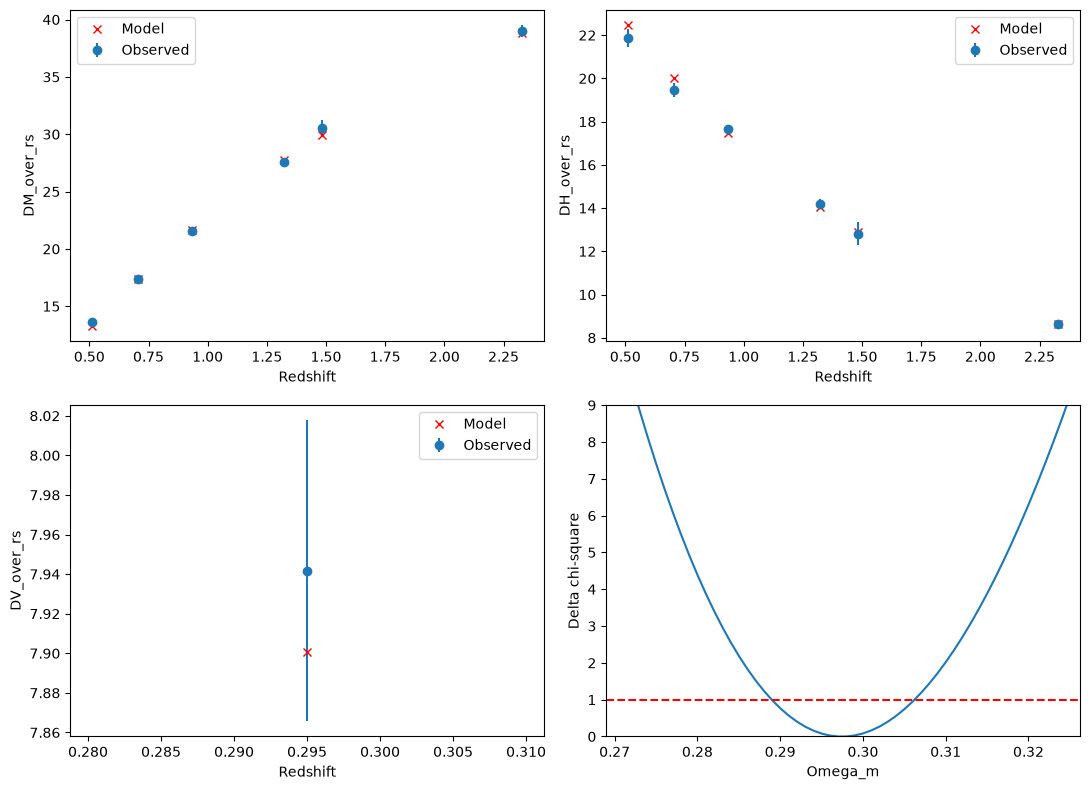

In [5]:
prediction = shape[:, best] * scale[best]
error = np.diag(cov)**0.5

plt.figure(figsize=(11, 8))

for i, name in enumerate(["DM_over_rs", "DH_over_rs", "DV_over_rs"]):
    selected = quantity == name

    plt.subplot(2, 2, i + 1)
    plt.errorbar(
        z[selected], y[selected], yerr=error[selected],
        fmt="o", label="Observed",
    )
    plt.plot(z[selected], prediction[selected], "rx", label="Model")
    plt.xlabel("Redshift")
    plt.ylabel(name)
    plt.legend()

plt.subplot(2, 2, 4)
plt.plot(omega_m, dchi2)
plt.plot([omega_m[0], omega_m[-1]], [1, 1], "r--")
plt.axis([lower - 0.02, upper + 0.02, 0, 9])
plt.xlabel("Omega_m")
plt.ylabel("Delta chi-square")

plt.tight_layout()
plt.show()

In [6]:
pd.DataFrame({
    "z": z,
    "quantity": quantity,
    "observed": y,
    "model": prediction,
    "residual": y - prediction,
    "error_diagonal": error,
}).to_csv("results/bao_residuals.csv", index=False)
